In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

/var/folders/q0/1kbzw8qs0cz6c2s1804scgyw0000gn/T/ipykernel_32728/3997216865.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([resnet_ious, dino_ious, baseline_ious], labels=['ResNet50', 'DINO', 'Baseline'])


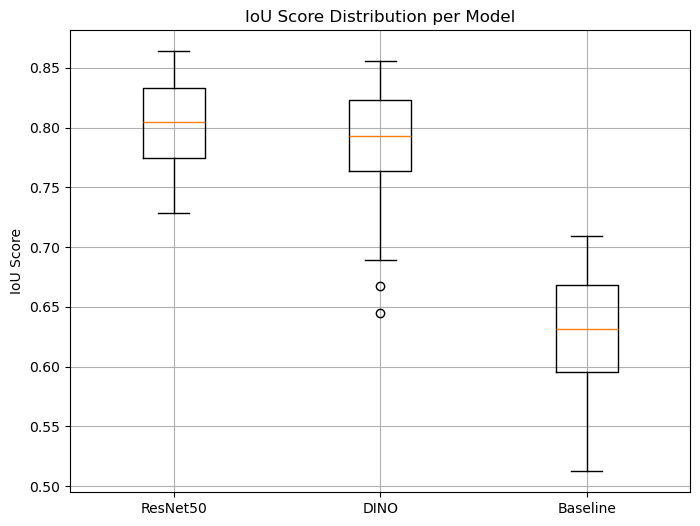

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

resnet_files = [
    'exports/unet/resnet_np/resnet50_4_False_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold2.npy',
    'exports/unet/resnet_np/resnet50_4_True_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy',
    'exports/unet/resnet_np/resnet50_8_False_adam_combined_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy'
]

dino_files = [
    'exports/unet/dino_np/dino_fdnzv5c2_e399_4_True_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy',
    'exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_dice_0.0005_512_seed42_epoch100_pat10_per_image_iou_fold2.npy',
    'exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy'
]

baseline_files = [
    'exports/baseline/baseline_np/per_image_iou_fold1_baseline.npy',
    'exports/baseline/baseline_np/per_image_iou_fold2_baseline.npy',
    'exports/baseline/baseline_np/per_image_iou_fold3_baseline.npy'
]

def load_iou_scores(file_list):
    ious = []
    for file in file_list:
        data = np.load(file, allow_pickle=True)
        scores = [item[1] for item in data]
        ious.extend(scores)
    return ious

# Load IoUs
resnet_ious = load_iou_scores(resnet_files)
dino_ious = load_iou_scores(dino_files)
baseline_ious = load_iou_scores(baseline_files)

# Plot boxplot with custom colors
data = [resnet_ious, dino_ious, baseline_ious]
labels = ['ResNet50', 'DINO', 'Baseline']
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red

plt.figure(figsize=(8, 6))
box = plt.boxplot(data, patch_artist=True, labels=labels)

# Apply colors to each box
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')

# Optionally color the whiskers, medians, etc.
for element in ['whiskers', 'caps', 'medians']:
    for item in box[element]:
        item.set_color('black')

plt.ylabel('IoU Score')
plt.title('IoU Score Distribution per Model')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()